# Piloto de Hardware y Modelo de Costo (D08 y D09)

Este notebook analiza visualmente las mediciones generadas por `scripts/03_pilot_tabpfn.py` en `results/pilot_log.csv`:

1. Piloto $m=1\text{k}$ y lotes (`1k / 2k / 5k`): tiempos de `fit`, segundos por cada 1.000 filas predichas (`predict_s_per_1k`), pico de VRAM y caso ULB Uniform ($m=1\text{k}$).
2. Escalamiento a $m=5\text{k}$ y $m=10\text{k}$, y `n_estimators` 4 vs 8: análisis de qué tamaños de contexto entran en los 6 GB de VRAM y el impacto de reducir el ensamble de 8 a 4 estimadores.
3. Modelo de costo $t(m, n_{\text{pred}})$ y proyección a 480 corridas TFM: estimación de GPU-horas totales comparando inferencia completa (`val + test`) frente a evaluación con submuestreo ponderado.

In [31]:
%load_ext autoreload
%autoreload 2

import matplotlib.pyplot as plt
import pandas as pd
import yaml
from IPython.display import display

from tpf.contexts.expected import expected_context_positives
from tpf.data.loaders import SPECS
from tpf.paths import CONFIGS, REPORTS, RESULTS

VRAM_LIMIT_MIB = 6 * 1024  # 6 GB (GTX 1660 Super)
NOMBRES = {"home_credit": "D0 Home Credit (120 feat.)", "ulb": "D1 ULB (30 feat.)"}
TABLAS = REPORTS / "tables"
FIG_DIR = REPORTS / "figures"
TABLAS.mkdir(parents=True, exist_ok=True)
FIG_DIR.mkdir(parents=True, exist_ok=True)

cfg = yaml.safe_load((CONFIGS / "default.yaml").read_text(encoding="utf-8"))
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")
plt.rcParams["figure.dpi"] = 110

log_path = RESULTS / "pilot_log.csv"
if not log_path.exists():
    raise FileNotFoundError(
        f"No se encontró {log_path}. Ejecutar primero: python scripts/03_pilot_tabpfn.py"
    )

df_pilot = pd.read_csv(log_path)
print(f"Filas cargadas desde {log_path.name}: {len(df_pilot)}")
display(df_pilot.head())

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
Filas cargadas desde pilot_log.csv: 72


,dataset,strategy,seed,m,n_pos,n_neg,pi_ctx,capped,n_estimators,n_pred,...,model_creation_s,fit_s,predict_s,predict_s_per_1k,fit_peak_allocated_mib,fit_peak_reserved_mib,predict_peak_allocated_mib,predict_peak_reserved_mib,status,error
0,ulb,uniform,0,1000,2,998,0.00,False,8,5000,...,0.00,6.05,85.02,17.00,40.90,42.00,156.70,230.00,complete,NaN
1,ulb,uniform,0,1000,2,998,0.00,False,8,5000,...,0.00,6.05,53.23,10.65,40.90,42.00,209.80,406.00,complete,NaN
2,ulb,uniform,0,1000,2,998,0.00,False,8,5000,...,0.00,6.05,41.82,8.36,40.90,42.00,368.30,762.00,complete,NaN
3,ulb,balanced,0,1000,295,705,0.29,True,8,5000,...,0.00,0.08,68.94,13.79,50.00,64.00,156.70,228.00,complete,NaN
4,ulb,balanced,0,1000,295,705,0.29,True,8,5000,...,0.00,0.08,53.65,10.73,50.00,64.00,209.80,406.00,complete,NaN


## 1.Piloto $m=1\text{k}$, tamaños de lote (`1k / 2k / 5k`) y caso ULB Uniform

Comparamos el tiempo de `fit`, la velocidad de inferencia (`predict_s_per_1k`) y el pico de VRAM reservada en $m=1000$ para lotes de 1.000, 2.000 y 5.000 filas.

In [32]:
m1k = df_pilot[df_pilot["m"] == 1000].copy()
cols_m1k = [
    "dataset",
    "strategy",
    "n_estimators",
    "n_pos",
    "pi_ctx",
    "capped",
    "batch_size",
    "fit_s",
    "predict_s",
    "predict_s_per_1k",
    "fit_peak_reserved_mib",
    "predict_peak_reserved_mib",
    "status",
]
display(m1k[cols_m1k].sort_values(["dataset", "n_estimators", "strategy", "batch_size"]))

,dataset,strategy,n_estimators,n_pos,pi_ctx,capped,batch_size,fit_s,predict_s,predict_s_per_1k,fit_peak_reserved_mib,predict_peak_reserved_mib,status
57,home_credit,balanced,4,500,0.50,False,1000,0.16,121.55,24.31,64.00,610.00,complete
58,home_credit,balanced,4,500,0.50,False,2000,0.16,94.84,18.97,64.00,"1,198.00",complete
59,home_credit,balanced,4,500,0.50,False,5000,0.16,60.63,12.12,64.00,"1,618.00",complete
54,home_credit,uniform,4,86,0.09,False,1000,0.18,121.42,24.28,64.00,610.00,complete
55,home_credit,uniform,4,86,0.09,False,2000,0.18,94.86,18.97,64.00,"1,198.00",complete
56,home_credit,uniform,4,86,0.09,False,5000,0.18,60.63,12.13,64.00,"1,618.00",complete
21,home_credit,balanced,8,500,0.50,False,1000,0.21,261.95,52.39,64.00,610.00,complete
22,home_credit,balanced,8,500,0.50,False,2000,0.21,203.13,40.62,64.00,"1,198.00",complete
23,home_credit,balanced,8,500,0.50,False,5000,0.21,128.47,25.69,64.00,"1,618.00",complete
18,home_credit,uniform,8,86,0.09,False,1000,0.26,260.88,52.18,64.00,610.00,complete


In [33]:
# Verificación teórica vs observada para ULB en m=1000
ulb_spec = SPECS["ulb"]
n_tr_ulb = int(round(ulb_spec.n_rows * cfg["split"]["train"]))
pos_tr_ulb = int(round(ulb_spec.n_pos * cfg["split"]["train"]))

for strat in ("uniform", "balanced"):
    exp = expected_context_positives(n_tr_ulb, pos_tr_ulb, 1000, strat)
    obs = m1k[(m1k["dataset"] == "ulb") & (m1k["strategy"] == strat)]["n_pos"].iloc[0]
    print(
        f"ULB {strat:8s} (m=1000) -> Esperado: {exp.n_pos:6.2f} pos "
        f"(pi_ctx={100 * exp.pi_ctx:5.2f}%, "
        f"P(0 pos)={100 * exp.p_zero_pos:5.2f}%, capped={exp.capped}) "
        f"| Observado semilla 0: {obs} pos"
    )

ULB uniform  (m=1000) -> Esperado:   1.73 pos (pi_ctx= 0.17%, P(0 pos)=17.68%, capped=False) | Observado semilla 0: 2 pos
ULB balanced (m=1000) -> Esperado: 295.00 pos (pi_ctx=29.50%, P(0 pos)= 0.00%, capped=True) | Observado semilla 0: 295 pos


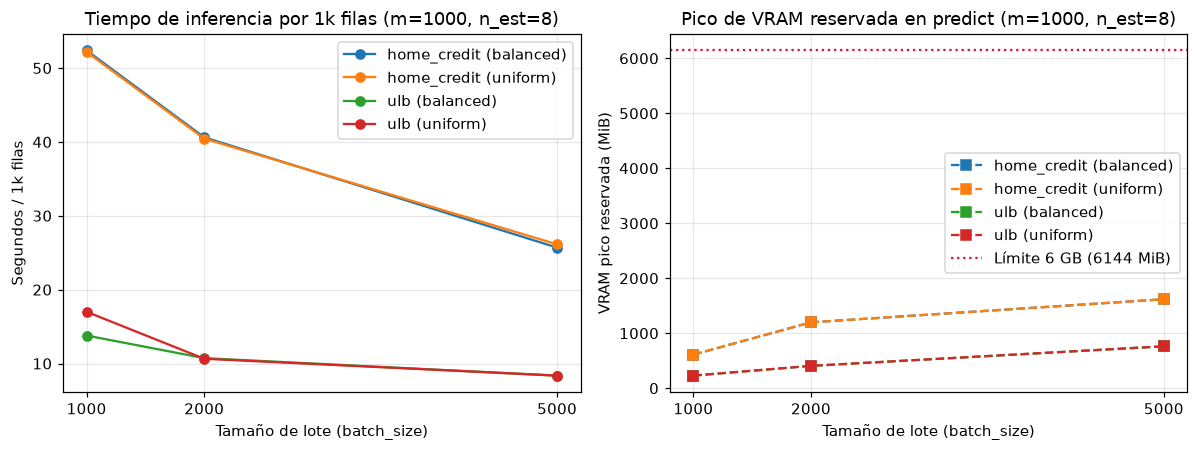

Guardada: figures/04_pilot_m1k_batches.png


In [34]:
# Efecto del batch_size en velocidad y VRAM para m=1000 (n_estimators=8)
m1k_ok = m1k[(m1k["status"] == "complete") & (m1k["n_estimators"] == 8)].copy()
if not m1k_ok.empty:
    fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
    for (ds, strat), grp in m1k_ok.groupby(["dataset", "strategy"]):
        grp = grp.sort_values("batch_size")
        label = f"{ds} ({strat})"
        axes[0].plot(grp["batch_size"], grp["predict_s_per_1k"], "o-", label=label)
        axes[1].plot(grp["batch_size"], grp["predict_peak_reserved_mib"], "s--", label=label)

    axes[0].set_title("Tiempo de inferencia por 1k filas (m=1000, n_est=8)")
    axes[0].set_xlabel("Tamaño de lote (batch_size)")
    axes[0].set_ylabel("Segundos / 1k filas")
    axes[0].set_xticks([1000, 2000, 5000])
    axes[0].grid(alpha=0.3)
    axes[0].legend()

    axes[1].axhline(VRAM_LIMIT_MIB, color="crimson", linestyle=":", label="Límite 6 GB (6144 MiB)")
    axes[1].set_title("Pico de VRAM reservada en predict (m=1000, n_est=8)")
    axes[1].set_xlabel("Tamaño de lote (batch_size)")
    axes[1].set_ylabel("VRAM pico reservada (MiB)")
    axes[1].set_xticks([1000, 2000, 5000])
    axes[1].grid(alpha=0.3)
    axes[1].legend()

    fig.tight_layout()
    out_fig1 = FIG_DIR / "04_pilot_m1k_batches.png"
    fig.savefig(out_fig1, bbox_inches="tight")
    plt.show()
    print("Guardada:", "figures/04_pilot_m1k_batches.png")

## 2. Escalamiento a $m=5\text{k}$ y $m=10\text{k}$ y comparación `n_estimators` 4 vs 8

Analizamos el comportamiento al escalar $m \in \{1000, 5000, 10000\}$ y comparamos el costo en tiempo y memoria entre `n_estimators=8` y `n_estimators=4`.

In [35]:
# Resumen consolidado por (dataset, m, n_estimators, batch_size) promediando estrategias completadas
resumen_piloto = (
    df_pilot.groupby(["dataset", "m", "n_estimators", "batch_size", "status"], dropna=False)
    .agg(
        n_casos=("strategy", "count"),
        fit_s_mean=("fit_s", "mean"),
        s_per_1k_mean=("predict_s_per_1k", "mean"),
        vram_fit_mib=("fit_peak_reserved_mib", "max"),
        vram_pred_mib=("predict_peak_reserved_mib", "max"),
    )
    .reset_index()
)
display(resumen_piloto)

resumen_piloto.to_csv(TABLAS / "tabla3_piloto_tiempos_vram.csv", index=False)
(TABLAS / "tabla3_piloto_tiempos_vram.md").write_text(
    resumen_piloto.to_markdown(index=False), encoding="utf-8"
)

,dataset,m,n_estimators,batch_size,status,n_casos,fit_s_mean,s_per_1k_mean,vram_fit_mib,vram_pred_mib
0,home_credit,1000,4,1000,complete,2,0.17,24.30,64.00,610.00
1,home_credit,1000,4,2000,complete,2,0.17,18.97,64.00,"1,198.00"
2,home_credit,1000,4,5000,complete,2,0.17,12.13,64.00,"1,618.00"
3,home_credit,1000,8,1000,complete,2,0.24,52.28,64.00,610.00
4,home_credit,1000,8,2000,complete,2,0.24,40.54,64.00,"1,198.00"
5,home_credit,1000,8,5000,complete,2,0.24,25.92,64.00,"1,618.00"
6,home_credit,5000,4,1000,complete,2,0.17,153.25,64.00,752.00
7,home_credit,5000,4,2000,complete,2,0.17,101.57,64.00,"1,272.00"
8,home_credit,5000,4,5000,complete,2,0.17,50.05,64.00,"2,012.00"
9,home_credit,5000,8,1000,complete,2,0.26,317.84,64.00,752.00


5585

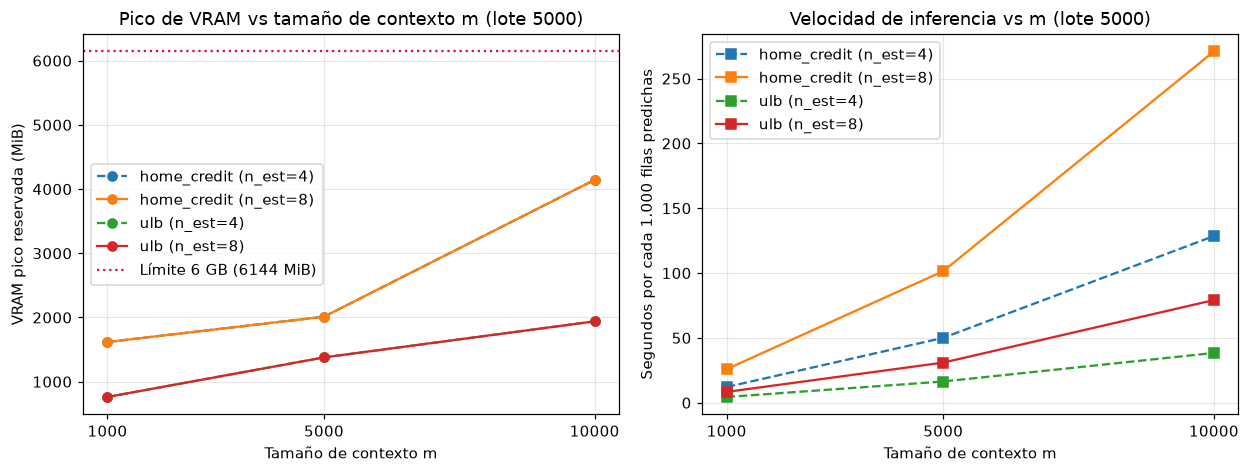

Guardada: figures/04_pilot_scaling_m_and_estimators.png


In [36]:
# Escalamiento de VRAM y tiempo según m (1k, 5k, 10k) y n_estimators (4 vs 8)
pref_batch = cfg["tabpfn"]["predict_batch_size"]
sub_scale = df_pilot[
    (df_pilot["status"] == "complete") & (df_pilot["batch_size"] == pref_batch)
].copy()
if sub_scale.empty:
    sub_scale = df_pilot[df_pilot["status"] == "complete"].copy()

agg_scale = (
    sub_scale.groupby(["dataset", "m", "n_estimators"])
    .agg(
        s_per_1k=("predict_s_per_1k", "mean"),
        fit_s=("fit_s", "mean"),
        vram_mib=("predict_peak_reserved_mib", "max"),
    )
    .reset_index()
)

fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.4))
for (ds, n_est), grp in agg_scale.groupby(["dataset", "n_estimators"]):
    grp = grp.sort_values("m")
    estilo = "-" if n_est == 8 else "--"
    label = f"{ds} (n_est={n_est})"
    axes[0].plot(grp["m"], grp["vram_mib"], marker="o", linestyle=estilo, label=label)
    axes[1].plot(grp["m"], grp["s_per_1k"], marker="s", linestyle=estilo, label=label)

axes[0].axhline(VRAM_LIMIT_MIB, color="crimson", linestyle=":", label="Límite 6 GB (6144 MiB)")
axes[0].set_title(f"Pico de VRAM vs tamaño de contexto m (lote {pref_batch})")
axes[0].set_xlabel("Tamaño de contexto m")
axes[0].set_ylabel("VRAM pico reservada (MiB)")
axes[0].set_xticks([1000, 5000, 10000])
axes[0].grid(alpha=0.3)
axes[0].legend()

axes[1].set_title(f"Velocidad de inferencia vs m (lote {pref_batch})")
axes[1].set_xlabel("Tamaño de contexto m")
axes[1].set_ylabel("Segundos por cada 1.000 filas predichas")
axes[1].set_xticks([1000, 5000, 10000])
axes[1].grid(alpha=0.3)
axes[1].legend()

fig.tight_layout()
out_fig2 = FIG_DIR / "04_pilot_scaling_m_and_estimators.png"
fig.savefig(out_fig2, bbox_inches="tight")
plt.show()
print("Guardada:", "figures/04_pilot_scaling_m_and_estimators.png")

## 3. Modelo de costo $t(m, n_{\text{pred}})$ y GPU-horas de la grilla completa (480 corridas TFM)

Para cada corrida real del protocolo experimental se predice sobre las particiones completas de `val` (20 %) y `test` (20 %), es decir el 40 % del dataset:

$$t(m, N_{\text{pred}}) = t_{\text{prep}} + t_{\text{fit}}(m, E) + \frac{N_{\text{val}} + N_{\text{test}}}{1000} \cdot s_{\text{por\_1k}}(m, E)$$

Comparamos dos regímenes de evaluación sobre las **480 corridas TFM** ($4\text{ datasets} \times 5\text{ estrategias} \times 3\text{ tamaños } m \times 8\text{ semillas}$):
- **Evaluación completa (`val + test` enteros)**: $\approx 113,9\text{k}$ filas en D1 (ULB) y $\approx 123,0\text{k}$ filas en D0 (Home Credit).
- **Opción A del Gate de Hardware (Evaluación con submuestreo ponderado)**: conservar todos los positivos de `val` y `test` más una muestra estratificada de negativos ($N_{\text{pred}} = 10.000$ filas totales por corrida, ponderando con `sample_weight`).

In [37]:
# Filas reales a predecir (val + test = 40% del dataset)
N_PRED_FULL = {
    "ulb": int(round(SPECS["ulb"].n_rows * (cfg["split"]["val"] + cfg["split"]["test"]))),
    "home_credit": int(
        round(SPECS["home_credit"].n_rows * (cfg["split"]["val"] + cfg["split"]["test"]))
    ),
}
N_PRED_WEIGHTED = 10_000  # 5k en val + 5k en test con sample_weight
N_RUNS_PER_CELL = len(cfg["context"]["strategies"]) * len(cfg["seeds"])  # 5 * 8 = 40 corridas

# Seleccionamos por cada (dataset, m, n_estimators) el lote óptimo completado (prefiriendo 5000)
ok = df_pilot[df_pilot["status"] == "complete"].copy()
ok["batch_pref"] = (ok["batch_size"] == pref_batch).astype(int)
best_cfg = (
    ok.sort_values(["batch_pref", "predict_s_per_1k"], ascending=[False, True])
    .groupby(["dataset", "m", "n_estimators"], as_index=False)
    .first()
)

cost_rows = []
for _, r in best_cfg.iterrows():
    ds = r["dataset"]
    n_full = N_PRED_FULL[ds]
    t_base = float(r["preparation_s"]) + float(r["fit_s"])
    s_1k = float(r["predict_s_per_1k"])

    t_run_full_s = t_base + (n_full / 1000.0) * s_1k
    t_run_weighted_s = t_base + (N_PRED_WEIGHTED / 1000.0) * s_1k

    cost_rows.append(
        {
            "dataset": ds,
            "m": int(r["m"]),
            "n_estimators": int(r["n_estimators"]),
            "batch_size": int(r["batch_size"]),
            "fit_s": round(float(r["fit_s"]), 2),
            "s_per_1k": round(s_1k, 3),
            "vram_peak_mib": round(float(r["predict_peak_reserved_mib"]), 1),
            "n_pred_full": n_full,
            "t_run_full_min": round(t_run_full_s / 60.0, 2),
            "gpu_h_40_runs_full": round((t_run_full_s * N_RUNS_PER_CELL) / 3600.0, 2),
            "t_run_weighted_min": round(t_run_weighted_s / 60.0, 2),
            "gpu_h_40_runs_weighted": round((t_run_weighted_s * N_RUNS_PER_CELL) / 3600.0, 2),
        }
    )

df_cost = pd.DataFrame(cost_rows).sort_values(["n_estimators", "dataset", "m"])
display(df_cost)

df_cost.to_csv(TABLAS / "tabla4_modelo_costo_gpu_horas.csv", index=False)
(TABLAS / "tabla4_modelo_costo_gpu_horas.md").write_text(
    df_cost.to_markdown(index=False), encoding="utf-8"
)

,dataset,m,n_estimators,batch_size,fit_s,s_per_1k,vram_peak_mib,n_pred_full,t_run_full_min,gpu_h_40_runs_full,t_run_weighted_min,gpu_h_40_runs_weighted
0,home_credit,1000,4,5000,0.16,12.12,"1,618.00",123004,24.93,16.62,2.10,1.40
2,home_credit,5000,4,5000,0.18,49.53,"1,982.00",123004,101.61,67.74,8.33,5.55
4,home_credit,10000,4,5000,0.22,127.81,"4,144.00",123004,262.11,174.74,21.38,14.25
6,ulb,1000,4,5000,0.15,4.39,762.00,113923,8.40,5.60,0.79,0.52
8,ulb,5000,4,5000,0.10,16.06,"1,378.00",113923,30.53,20.35,2.71,1.81
10,ulb,10000,4,5000,0.09,37.78,"1,940.00",113923,71.77,47.85,6.33,4.22
1,home_credit,1000,8,5000,0.21,25.69,"1,618.00",123004,52.77,35.18,4.37,2.92
3,home_credit,5000,8,5000,0.26,98.99,"1,982.00",123004,203.03,135.35,16.59,11.06
5,home_credit,10000,8,5000,0.56,270.45,"4,144.00",123004,554.55,369.70,45.18,30.12
7,ulb,1000,8,5000,0.08,8.36,762.00,113923,15.90,10.60,1.42,0.95


2869

In [38]:
# Proyección a D0+D1 (240 corridas) y a la grilla completa TFM (480 corridas).
totales = (
    df_cost.groupby("n_estimators")
    .agg(
        gpu_h_d0_d1_full=("gpu_h_40_runs_full", "sum"),
        gpu_h_d0_d1_weighted=("gpu_h_40_runs_weighted", "sum"),
    )
    .reset_index()
)
# (480 corridas = 2x el bloque D0+D1):
totales["gpu_h_480_full_est"] = (2.0 * totales["gpu_h_d0_d1_full"]).round(1)
totales["gpu_h_480_weighted_est"] = (2.0 * totales["gpu_h_d0_d1_weighted"]).round(1)
display(totales)

,n_estimators,gpu_h_d0_d1_full,gpu_h_d0_d1_weighted,gpu_h_480_full_est,gpu_h_480_weighted_est
0,4,332.90,27.75,665.80,55.50
1,8,688.16,57.14,"1,376.30",114.30
